# Time Series Analysis

In [ ]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from scipy.signal import butter, filtfilt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [160]:
FOLDER_PATH = Path("../../data/time-series")  

subdirs = sorted([d for d in FOLDER_PATH.iterdir() if d.is_dir()])

print(f"Total directories found: {len(subdirs)}\n")

subject_infos = []

# Extract subject_id and hadm_id (record) from directory names
for subdir in subdirs:
    # Split directory name: format is "subjectid_hadmid"
    parts = subdir.name.split('_')
    if len(parts) >= 2:
        subject_id = parts[0]
        hadm_id = parts[1]  # This is the record/admission ID
        subject_infos.append({
            'subject_id': subject_id,
            'record_name': hadm_id,
            'folder_name': subdir.name
        })

# Convert to DataFrame for easier manipulation
subject_infos_df = pd.DataFrame(subject_infos)

subject_infos_df.shape

Total directories found: 1786



(1786, 3)

In [161]:
timeseries_dict = {}

for record in subject_infos_df['record_name'].unique():
    record_path = FOLDER_PATH / f"{subject_infos_df[subject_infos_df['record_name'] == record]['folder_name'].values[0]}" / record
    try:
        # Read the entire signal
        signal, fields = wfdb.rdsamp(str(record_path))
        fs = fields['fs']  # Sampling frequency
        
        # Use the actual length of the signal
        num_samples = signal.shape[0]
        num_channels = signal.shape[1]
        duration_seconds = num_samples / fs
        
        # Create time axis for the entire signal
        time_axis = np.arange(num_samples) / fs
        
        # Create a unique time series concatenating all channels sequentially
        # Flatten column-wise: Ch1 samples, then Ch2 samples, then Ch3 samples, etc.
        concatenated_signal = signal.flatten(order='F')  # 'F' for Fortran-style (column-major)
        
        total_length = concatenated_signal.shape[0]
        
        # Calculate start time (in seconds) for each channel in the concatenated signal
        signal_start_times = []
        for i in range(num_channels):
            start_sample = i * num_samples
            start_time = start_sample / fs
            signal_start_times.append({
                'channel_index': i,
                'channel_name': fields['sig_name'][i],
                'start_sample': start_sample,
                'start_time_seconds': start_time,
                'end_sample': start_sample + num_samples - 1,
                'end_time_seconds': (start_sample + num_samples - 1) / fs
            })
        
        # Store in dictionary
        timeseries_dict[record] = {
            'signal': concatenated_signal,
            'fs': fs,
            'num_channels': num_channels,
            'samples_per_channel': num_samples,
            'total_length': total_length,
            'duration_seconds': duration_seconds,
            'signal_names': fields['sig_name'],
            'signal_start_times': signal_start_times
        }
        
        print(f"Record: {record}")
        print(f"  Channels: {num_channels}")
        print(f"  Samples per channel: {num_samples}")
        print(f"  Total concatenated length: {total_length} (= {num_channels} × {num_samples})")
        print(f"  Duration per channel: {duration_seconds:.2f} seconds")
        print(f"  Signal start times:")
        for st in signal_start_times[:3]:  # Show first 3 channels
            print(f"    {st['channel_name']}: starts at sample {st['start_sample']} (time: {st['start_time_seconds']:.2f}s)")
        if num_channels > 3:
            print(f"    ... and {num_channels - 3} more channels")
        print()

    except Exception as e:
        print(f"Could not read record {record}: {e}")

print(f"\nTotal records processed: {len(timeseries_dict)}")

Record: 42546971
  Channels: 12
  Samples per channel: 5000
  Total concatenated length: 60000 (= 12 × 5000)
  Duration per channel: 10.00 seconds
  Signal start times:
    I: starts at sample 0 (time: 0.00s)
    II: starts at sample 5000 (time: 10.00s)
    III: starts at sample 10000 (time: 20.00s)
    ... and 9 more channels

Record: 46167614
  Channels: 12
  Samples per channel: 5000
  Total concatenated length: 60000 (= 12 × 5000)
  Duration per channel: 10.00 seconds
  Signal start times:
    I: starts at sample 0 (time: 0.00s)
    II: starts at sample 5000 (time: 10.00s)
    III: starts at sample 10000 (time: 20.00s)
    ... and 9 more channels

Record: 47527771
  Channels: 12
  Samples per channel: 5000
  Total concatenated length: 60000 (= 12 × 5000)
  Duration per channel: 10.00 seconds
  Signal start times:
    I: starts at sample 0 (time: 0.00s)
    II: starts at sample 5000 (time: 10.00s)
    III: starts at sample 10000 (time: 20.00s)
    ... and 9 more channels

Record: 45

## Example of ECG Signal

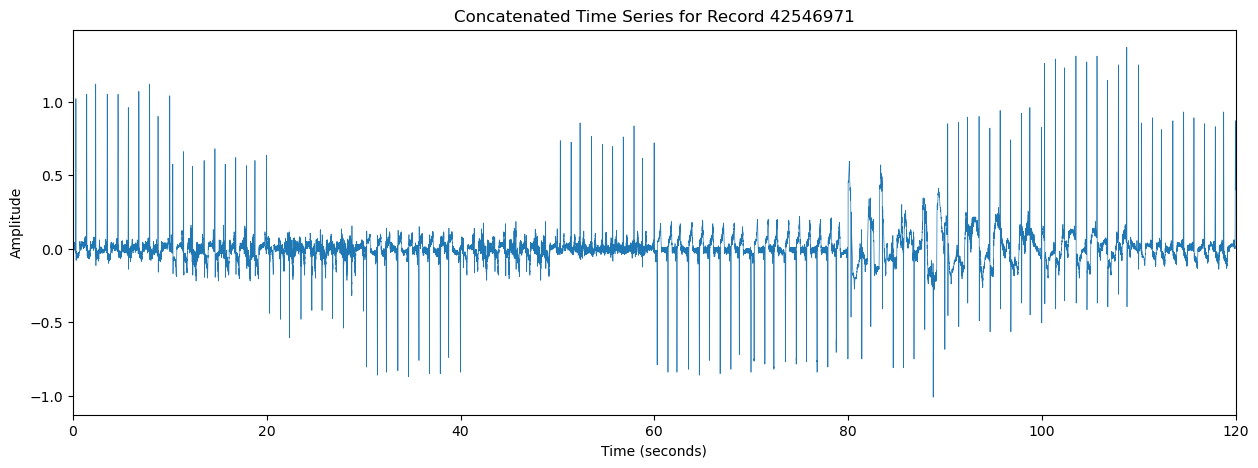

In [162]:

#Plot the first complete concatenated time series
first_record = list(timeseries_dict.keys())[0]
ts_data = timeseries_dict[first_record]
time_axis = np.arange(ts_data['total_length']) / ts_data['fs']
plt.figure(figsize=(15, 5))
plt.plot(time_axis, ts_data['signal'], linewidth=0.5)
plt.title(f"Concatenated Time Series for Record {first_record}")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.xlim(0, ts_data['duration_seconds'] * ts_data['num_channels'])
plt.show()

## Time Series Understanding

Given a time series, it is interesting to understand the behaviour of the it; to do so we can check for some particular informations:
- **Trends**
- **Seasonality**
- **Cyclicity**

### Triple Exponential Smoothing (Holt-Winters method)

In [ ]:
def hw_method(series, seasonal_periods, trend='add', seasonal='add'):
    #TODO: Implement Holt-Winters method for time series smoothing

## Noise removal

### Rolling window approach

The first idea to remove noise in the time series is to use a rolling window (with a defeault value of 5), and smooth the curve. 

In [163]:
# Remove noise in the time series by applying a rolling window average filter
def moving_average(signal, window_size=5):
    """
    Apply moving average filter to a numpy array signal.
    
    Parameters:
    -----------
    signal : numpy.ndarray
        Input signal
    window_size : int
        Size of the moving average window
        
    Returns:
    --------
    pandas.Series
        Filtered signal with NaN at edges
    """
    # Convert to pandas Series for rolling window operations
    signal_series = pd.Series(signal)
    
    # Standardize: (x - mean) / std
    standardized = (signal_series - signal_series.mean()) / signal_series.std()
    
    # Apply rolling window average
    filtered = standardized.rolling(window=window_size, center=True).mean()
    
    return filtered


### Low/High-Pass and Band-Pass filters

Another option is to use *Low-Pass*, *High-Pass* and *Band-Pass* filters to remove the noise on ECG signals.
- **Low-Pass filter**: A Low-Pass filter (LPF) is a filter that passes signals with a frequency lower than a selected cutoff frequency and attenuates signals with frequencies higher than the cutoff frequency.
- **High-Pass filter**: A High-Pass filter (HPF) is an electronic filter that passes signals with a frequency higher than a certain cutoff frequency and attenuates signals with frequencies lower than the cutoff frequency.
- **Band-Pass filter**: A Band-Pass filter allows through components in a specified band of frequencies, called its passband but blocks components with frequencies above or below this band. This contrasts with a high-pass filter, which allows through components with frequencies above a specific frequency, and a low-pass filter, which allows through components with frequencies below a specific frequency.

In [164]:
def low_pass_filter(signal, fs, cutoff=30, order=5):
    """
    Apply a low-pass Butterworth filter to the signal.

    Parameters:
    signal : numpy.ndarray
        Input signal
    fs : float
        Sampling frequency
    cutoff : float
        Cutoff frequency of the filter
    order : int
        Order of the filter
    Returns:
    numpy.ndarray
        Filtered signal
    """
    # Calculate the Nyquist frequency
    nyquist = 0.5 * fs

    # Normalized cutoff frequency
    normal_cutoff = cutoff / nyquist

    # Get the filter coefficients
    b, a = butter(order, normal_cutoff, btype='low', analog=False)

    # Apply the filter
    filtered_signal = filtfilt(b, a, signal)
    return filtered_signal

def high_pass_filter(signal, fs, cutoff=0.5, order=5):
    """
    Apply a high-pass Butterworth filter to the signal.

    Parameters:
    signal : numpy.ndarray
        Input signal
    fs : float
        Sampling frequency
    cutoff : float
        Cutoff frequency of the filter
    order : int
        Order of the filter
    Returns:
    numpy.ndarray
        Filtered signal
    """
    # Calculate the Nyquist frequency
    nyquist = 0.5 * fs

    # Normalized cutoff frequency
    normal_cutoff = cutoff / nyquist

    # Get the filter coefficients
    b, a = butter(order, normal_cutoff, btype='high', analog=False)

    # Apply the filter
    filtered_signal = filtfilt(b, a, signal)
    return filtered_signal

def band_pass_filter(signal, fs, lowcut=0.5, highcut=30, order=5):
    """
    Apply a band-pass Butterworth filter to the signal.

    Parameters:
    signal : numpy.ndarray
        Input signal
    fs : float
        Sampling frequency
    lowcut : float
        Low cutoff frequency of the filter
    highcut : float
        High cutoff frequency of the filter
    order : int
        Order of the filter
    Returns:
    numpy.ndarray
        Filtered signal
    """
    # Calculate the Nyquist frequency
    nyquist = 0.5 * fs

    # Normalized cutoff frequencies
    low = lowcut / nyquist
    high = highcut / nyquist

    # Get the filter coefficients
    b, a = butter(order, [low, high], btype='band')

    # Apply the filter
    filtered_signal = filtfilt(b, a, signal)
    return filtered_signal


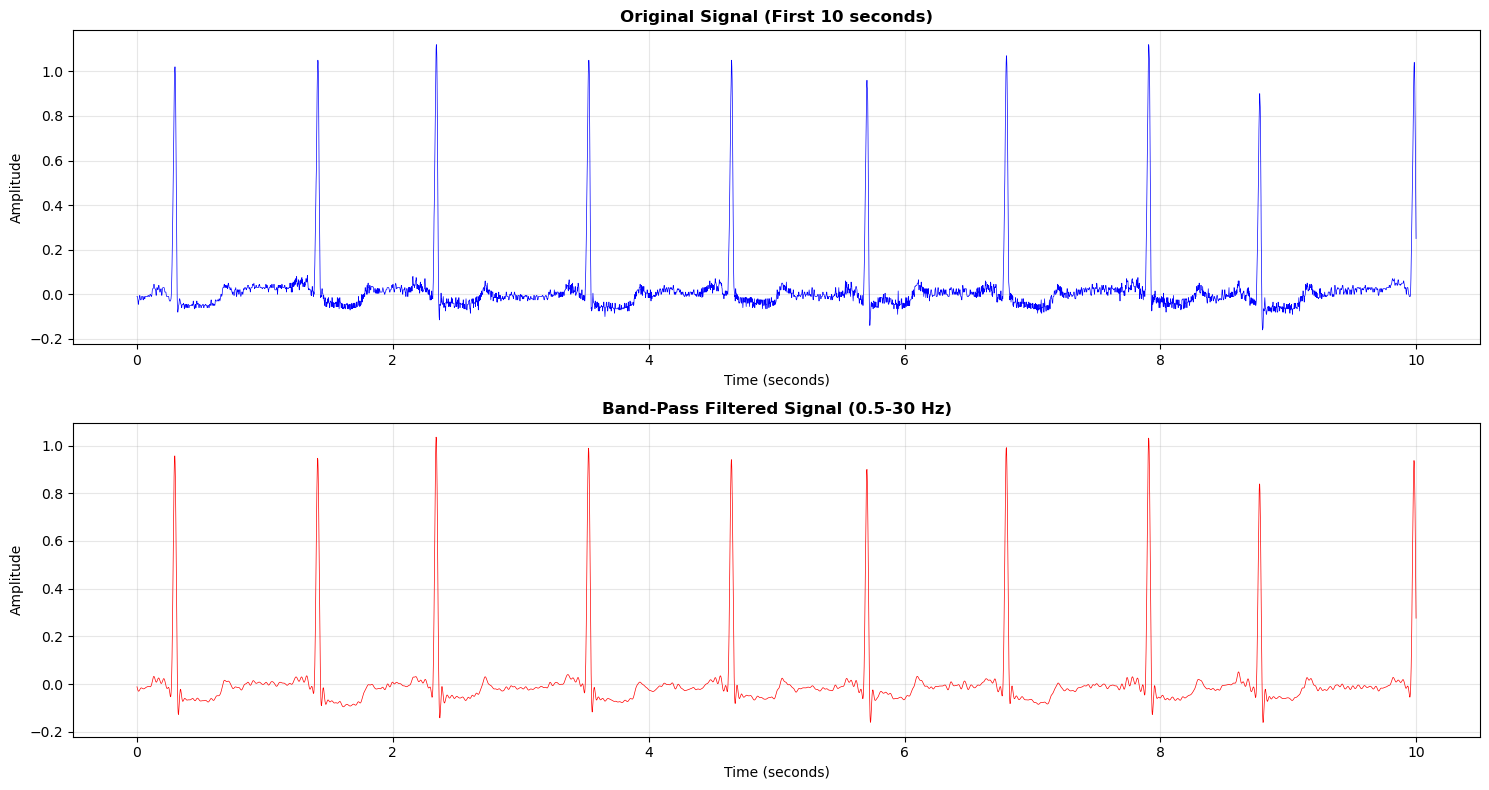

In [165]:
filtered_signal_bp = band_pass_filter(ts_data['signal'], fs=ts_data['fs'], lowcut=0.5, highcut=30, order=5)

# Plot comparison for first 10 seconds
fs = ts_data['fs']
samples_10s = int(10 * fs)
time_10s = np.arange(samples_10s) / fs

plt.figure(figsize=(15, 8), dpi=100)

# Original signal
plt.subplot(2, 1, 1)
plt.plot(time_10s, ts_data['signal'][:samples_10s], linewidth=0.5, color='blue')
plt.title('Original Signal (First 10 seconds)', fontweight='bold')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)

# Filtered signal
plt.subplot(2, 1, 2)
plt.plot(time_10s, filtered_signal_bp[:samples_10s], linewidth=0.5, color='red')
plt.title('Band-Pass Filtered Signal (0.5-30 Hz)', fontweight='bold')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()